# ACWR exploration

Validating `daily_load` and `acwr_rolling` on a small hand-checked example and on 60 days of synthetic training data.

Pipeline: activities → TRIMP per activity → daily load → ACWR

## Setup

The notebook runs from `notebooks/`, so `backend/` is added to the path
to make the `app` package importable.

In [ ]:
import sys
sys.path.insert(0, "..")  

## 1. Small example

Three activities, two of them on the same day.

Expected: 1 Sep = 50 + 30 = 80, rest days filled with 0 up to `end`.

In [4]:
import pandas as pd
from app.metrics.acwr import acwr_rolling, daily_load

loads = pd.Series(
    [50.0, 30.0, 40.0],
    index=pd.to_datetime(["2026-09-01 07:00", "2026-09-01 18:00", "2026-09-03 07:00"]),
)
daily = daily_load(loads, end="2026-09-05")
daily

2026-09-01    80.0
2026-09-02     0.0
2026-09-03    40.0
2026-09-04     0.0
2026-09-05     0.0
Freq: D, dtype: float64

`acwr_rolling` returns a DataFrame with one row per day and three columns:
acute load (7-day mean), chronic load (28-day mean) and their ratio.

In [5]:
result = acwr_rolling(daily)
result

,acute,chronic,acwr
2026-09-01,80.0,80.0,1.0
2026-09-02,40.0,40.0,1.0
2026-09-03,40.0,40.0,1.0
2026-09-04,30.0,30.0,1.0
2026-09-05,24.0,24.0,1.0


In [6]:
type(result)
result.dtypes
result.index

DatetimeIndex(['2026-09-01', '2026-09-02', '2026-09-03', '2026-09-04',
               '2026-09-05'],
              dtype='datetime64[us]', freq='D')

## 2. Synthetic data

60 days from the generator, with known phases: base, build-up, overload,
detraining and return. Banister TRIMP with resting HR 65, max HR 195.

In [7]:
from app.generators.synthetic import generate_activities
from app.metrics.trimp import banister_trimp

activities = generate_activities()

loads = pd.Series(
    [banister_trimp(a.samples, 65, 195, "female") for a in activities],
    index=[a.start for a in activities],
)
daily = daily_load(loads)
result = acwr_rolling(daily)

A first look at the numbers, and the days that fall into the high-risk zone (ACWR > 1.5).

In [ ]:
result.head(10)            
result.iloc[25:35]     
result.describe()         
result[result["acwr"] > 1.5]   

,acute,chronic,acwr
2026-09-28,94.137506,61.609026,1.527982
2026-09-29,96.271919,62.584138,1.538280
2026-09-30,99.870922,63.933765,1.562100


## 3. Acute vs chronic load

Acute load reacts quickly to changes in training, chronic load follows slowly because it averages four weeks.

<Axes: >

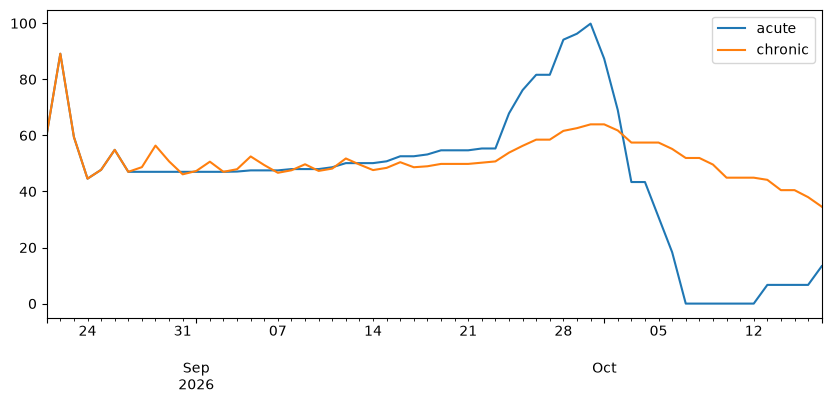

In [9]:
result[["acute", "chronic"]].plot(figsize=(10, 4))

## 4. ACWR

Dashed lines mark the commonly used zones: below 0.8 (undertraining) and above 1.5 (higher injury risk)

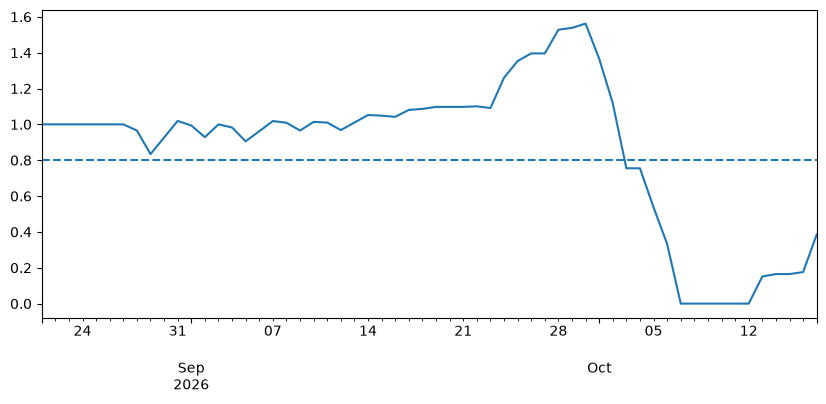

In [11]:
ax = result["acwr"].plot(figsize=(10, 4))
ax.axhline(0.8, linestyle="--")


## Findings

- **First week:** ACWR is always 1.0, because both windows contain the
  same days. This means "not enough data", not a perfect load.
- **Overload week:** ACWR rises to about 1.55, above the 1.5 risk threshold.
- **Detraining:** acute load drops to 0 faster than chronic load, so ACWR falls to 0.
- **Steps in the curve:** ACWR jumps when a hard day leaves the 7-day window. EWMA (Exponentially Weighted Moving Average) should be smoother.

### Limitations

- Days without a recorded activity count as rest days.
- TRIMP underestimates strength training.